In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import glob
import subprocess


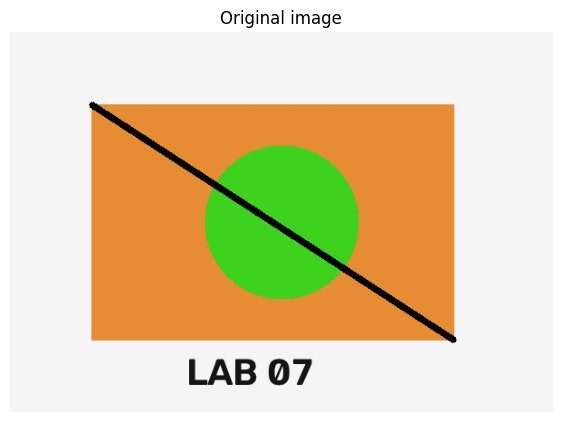

In [2]:
image = np.full((420, 600, 3), 245, dtype=np.uint8)
cv2.rectangle(image, (90, 80), (490, 340), (50, 140, 230), -1)
cv2.circle(image, (300, 210), 85, (30, 210, 60), -1)
cv2.line(image, (90, 80), (490, 340), (0, 0, 0), 5)
cv2.putText(image, "LAB 07", (195, 390), cv2.FONT_HERSHEY_SIMPLEX, 1.4, (20, 20, 20), 3)
height, width = image.shape[:2]
def show(title, image):
    plt.figure(figsize=(7, 5))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()
show("Original image", image)

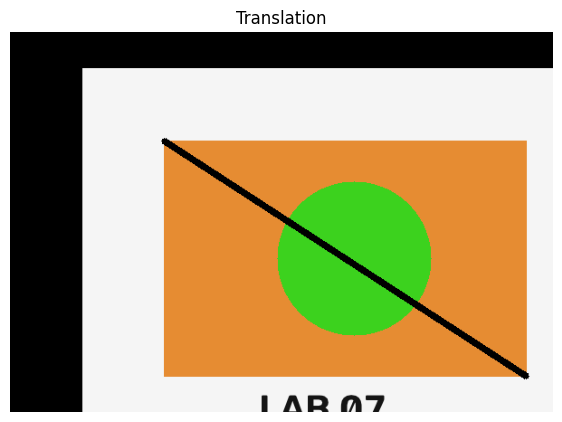

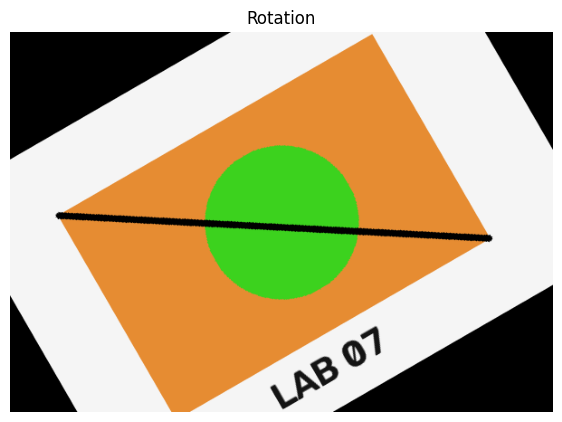

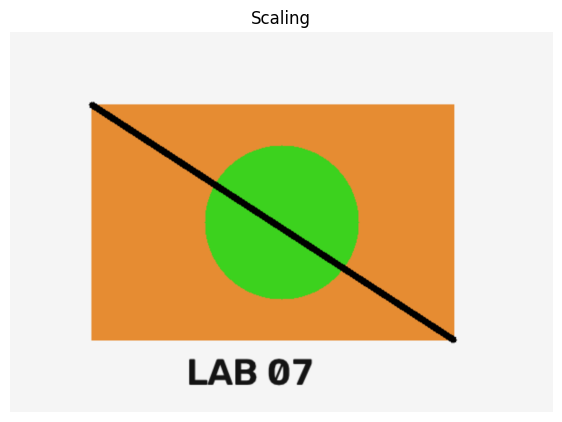

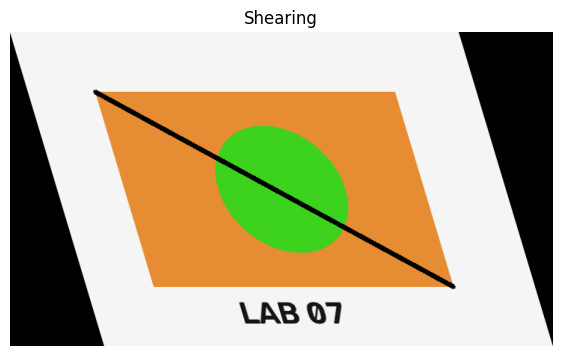

In [3]:
translation = np.float32([[1, 0, 80], [0, 1, 40]])
translated = cv2.warpAffine(image, translation, (width, height))
rotation = cv2.getRotationMatrix2D((width / 2, height / 2), 30, 1)
rotated = cv2.warpAffine(image, rotation, (width, height))
scaled = cv2.resize(image, None, fx=1.5, fy=1.5)
shear = np.float32([[1, 0.3, 0], [0, 1, 0]])
sheared = cv2.warpAffine(image, shear, (width + int(height * 0.3), height))
for name, result in [("Translation", translated), ("Rotation", rotated), ("Scaling", scaled), ("Shearing", sheared)]:
    show(name, result)


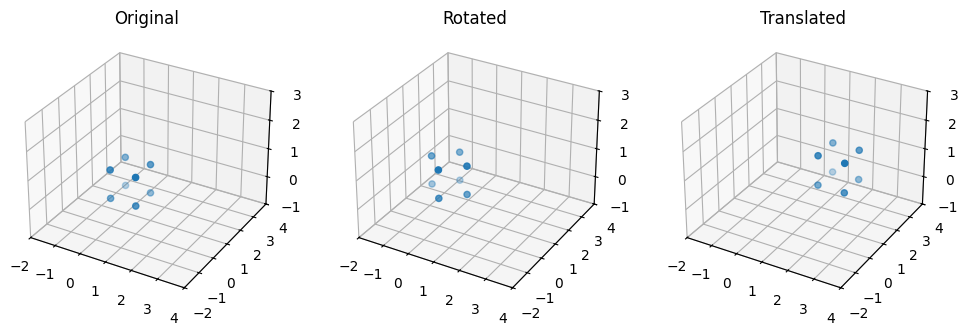

In [4]:
from mpl_toolkits.mplot3d import Axes3D
points = np.array([[0, 0, 0], [1, 0, 0], [1, 1, 0], [0, 1, 0], [0, 0, 1], [1, 0, 1], [1, 1, 1], [0, 1, 1]])
angle = np.radians(45)
rotation3d = np.array([[np.cos(angle), -np.sin(angle), 0], [np.sin(angle), np.cos(angle), 0], [0, 0, 1]])
rotated3d = points @ rotation3d.T
moved3d = points + [2, 0, 1]
fig = plt.figure(figsize=(12, 4))
for i, (name, data) in enumerate([("Original", points), ("Rotated", rotated3d), ("Translated", moved3d)]):
    ax = fig.add_subplot(1, 3, i + 1, projection="3d")
    ax.scatter(data[:, 0], data[:, 1], data[:, 2])
    ax.set_title(name)
    ax.set_xlim(-2, 4)
    ax.set_ylim(-2, 4)
    ax.set_zlim(-1, 3)
plt.show()


In [5]:
point = np.array([30, 50])
homogeneous = np.array([30, 50, 1])
transform = np.array([[1, 0, 40], [0, 1, 20], [0, 0, 1]])
result = transform @ homogeneous
print("Original point:", point)
print("Homogeneous point:", homogeneous)
print("Translated point:", result[:2] / result[2])
print("The extra coordinate allows translation and perspective transformations using matrix multiplication.")


Original point: [30 50]
Homogeneous point: [30 50  1]
Translated point: [70. 70.]
The extra coordinate allows translation and perspective transformations using matrix multiplication.


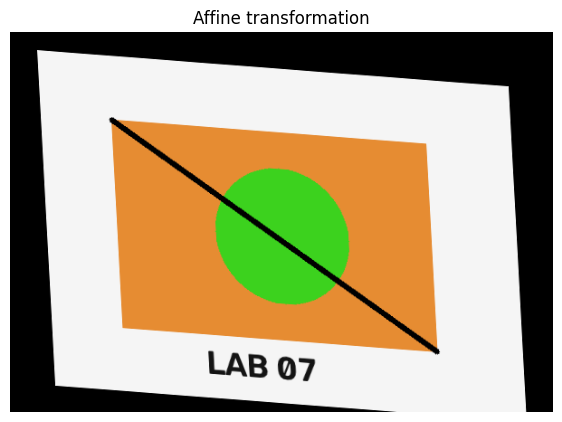

Straight lines remain straight under affine transformations.


In [6]:
source = np.float32([[0, 0], [width - 1, 0], [0, height - 1]])
destination = np.float32([[30, 20], [width - 50, 60], [50, height - 30]])
affine_matrix = cv2.getAffineTransform(source, destination)
affine_image = cv2.warpAffine(image, affine_matrix, (width, height))
show("Affine transformation", affine_image)
print("Straight lines remain straight under affine transformations.")


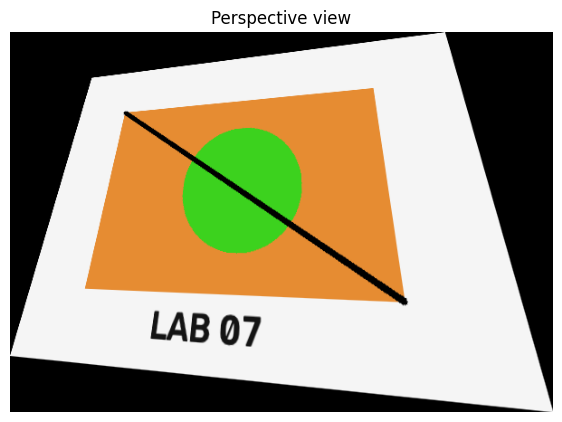

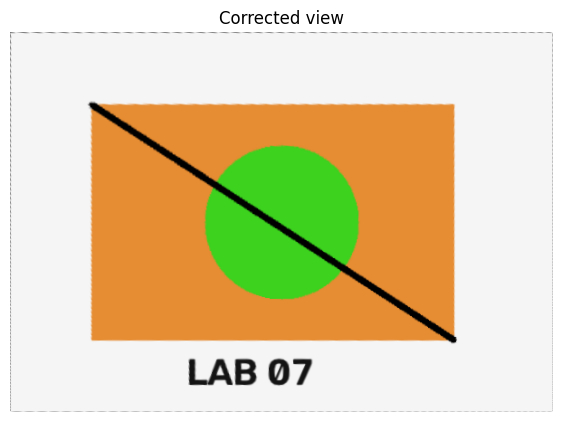

In [7]:
source = np.float32([[0, 0], [width - 1, 0], [width - 1, height - 1], [0, height - 1]])
destination = np.float32([[width * 0.15, height * 0.12], [width * 0.8, 0], [width - 1, height - 1], [0, height * 0.85]])
homography = cv2.getPerspectiveTransform(source, destination)
tilted = cv2.warpPerspective(image, homography, (width, height))
corrected = cv2.warpPerspective(tilted, np.linalg.inv(homography), (width, height))
show("Perspective view", tilted)
show("Corrected view", corrected)


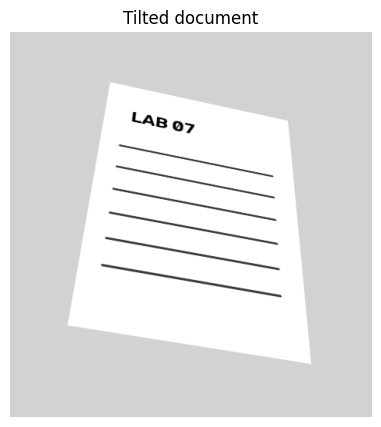

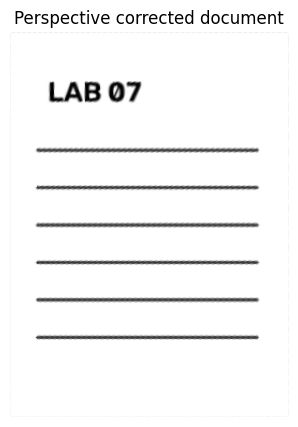

True

In [8]:
page = np.full((360, 260, 3), 255, dtype=np.uint8)
cv2.putText(page, "LAB 07", (35, 65), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 0), 2)
for y in range(110, 310, 35):
    cv2.line(page, (25, y), (230, y), (60, 60, 60), 2)
source_corners = np.float32([[0, 0], [259, 0], [259, 359], [0, 359]])
tilted_corners = np.float32([[130, 65], [360, 115], [390, 430], [75, 380]])
matrix = cv2.getPerspectiveTransform(source_corners, tilted_corners)
document = cv2.warpPerspective(page, matrix, (470, 500), borderValue=(210, 210, 210))
corrected = cv2.getPerspectiveTransform(tilted_corners, source_corners)
unwrapped = cv2.warpPerspective(document, corrected, (260, 360))
show("Tilted document", document)
show("Perspective corrected document", unwrapped)
cv2.imwrite("unwrapped.jpg", unwrapped)

In [9]:
chessboard_size = (9, 6)
object_points = []
image_points = []
grid = np.zeros((chessboard_size[0] * chessboard_size[1], 3), np.float32)
grid[:, :2] = np.mgrid[0:chessboard_size[0], 0:chessboard_size[1]].T.reshape(-1, 2)
image_size = None
for filename in glob.glob("calibration/*.jpg"):
    frame = cv2.imread(filename)
    if frame is None:
        continue
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    found, corners = cv2.findChessboardCorners(gray, chessboard_size)
    if found:
        corners = cv2.cornerSubPix(gray, corners, (11, 11), (-1, -1), (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001))
        object_points.append(grid.copy())
        image_points.append(corners)
        image_size = gray.shape[::-1]
if object_points:
    error, camera_matrix, distortion, _, _ = cv2.calibrateCamera(object_points, image_points, image_size, None, None)
    np.savez("camera_calibration.npz", camera_matrix=camera_matrix, distortion=distortion)
    print("Reprojection error:", error)
    print("Camera matrix:\n", camera_matrix)
    print("Distortion:\n", distortion)
else:
    print("Calibration skipped: add chessboard photos to calibration/ to run it.")

Calibration skipped: add chessboard photos to calibration/ to run it.


In [10]:
import sys
calibration_file = Path("camera_calibration.npz")
if "google.colab" in sys.modules:
    print("Live cv2.VideoCapture webcam processing requires a local Python environment.")
elif not calibration_file.exists():
    print("Run calibration with chessboard photos before undistorting the webcam.")
else:
    calibration = np.load(calibration_file)
    camera_matrix = calibration["camera_matrix"]
    distortion = calibration["distortion"]
    cap = cv2.VideoCapture(0)
    if cap.isOpened():
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            undistorted = cv2.undistort(frame, camera_matrix, distortion)
            cv2.imshow("Original and Undistorted", np.hstack((frame, undistorted)))
            if cv2.waitKey(1) & 0xFF == ord("q"):
                break
        cap.release()
        cv2.destroyAllWindows()
    else:
        print("No webcam available.")

Live cv2.VideoCapture webcam processing requires a local Python environment.


In [11]:
project = Path("colmap_project")
images = project / "images"
images.mkdir(parents=True, exist_ok=True)
database = project / "database.db"
sparse = project / "sparse"
dense = project / "dense"
sparse.mkdir(exist_ok=True)
dense.mkdir(exist_ok=True)
print("Put multiple overlapping photos into:", images.resolve())


Put multiple overlapping photos into: /content/colmap_project/images


In [12]:
import shutil
def colmap(*args):
    subprocess.run(["colmap", *map(str, args)], check=True)
if shutil.which("colmap") is None:
    print("COLMAP is not installed. Install it and add overlapping photos to colmap_project/images.")
elif len(list(images.glob("*.*"))) < 2:
    print("COLMAP skipped: add at least two overlapping photos to colmap_project/images.")
else:
    colmap("feature_extractor", "--database_path", database, "--image_path", images)
    colmap("exhaustive_matcher", "--database_path", database)
    colmap("mapper", "--database_path", database, "--image_path", images, "--output_path", sparse)

COLMAP is not installed. Install it and add overlapping photos to colmap_project/images.


In [13]:
models = sorted(p for p in sparse.iterdir() if p.is_dir())
if shutil.which("colmap") is None or not models:
    print("Dense reconstruction skipped: a successful COLMAP sparse model is required.")
else:
    model = models[0]
    colmap("image_undistorter", "--image_path", images, "--input_path", model, "--output_path", dense, "--output_type", "COLMAP")
    colmap("patch_match_stereo", "--workspace_path", dense, "--workspace_format", "COLMAP")
    colmap("stereo_fusion", "--workspace_path", dense, "--workspace_format", "COLMAP", "--input_type", "geometric", "--output_path", dense / "fused.ply")
    colmap("poisson_mesher", "--input_path", dense / "fused.ply", "--output_path", dense / "mesh.ply")
    print("Point cloud:", dense / "fused.ply")
    print("Mesh:", dense / "mesh.ply")

Dense reconstruction skipped: a successful COLMAP sparse model is required.
